<!-- This is a template that you should use to generate your lab reports for AE801 course work-->
# **Lab Report: Interpolation**

# Required packages

In [3]:
# do not change line below
from google.colab import files

# import required packages here
import numpy as np
import matplotlib.pyplot as plt

# Problem statement:
1. Construct NACA 4 digit series airfoil with Airfoil equations.
2. Reconstruct the same using Lagranges Interpolation method.
3. Calulate the Max and RMS errors and compare the both airfoils.
4. How to improve errors?
5. Reconstruct the same using cubic spline and compare.

# Approach and numerical method

### NACA 4 digit series Airfoils:
For a NACA 4 digit series Airfoil XXXX:\
Where, \
First digit says, Maximum camber as a percentage of the chord.\
Second digit says: The distance of Maximum camber from airfoil leading edge in tenths of chord.\
Last 2 digit says, Maximum thickness as percent of the chord.

###  Formulae for Airfoil:
1. Percentage of y w.r.t chord:

$y_t = 5t \cdot \left(0.2969 \sqrt{x} - 0.1260 x - 0.3516 x^2 + 0.2843 x^3 - 0.1036 x^4 \right)$\
where,\
x: position along the chord.\
$y_t$: half-thickness at a given x.\
t: maximum thickness as function of chord.

2. Mean camber line:\
$
y_c(x) = 
\begin{cases} 
\dfrac{m}{p^2} \left( 2p{x} - {x}^2 \right) c, & 0 \le x < p \\[12pt]
\dfrac{m}{(1 - p)^2} \left( (1 - 2p) + 2p{x} - {x}^2 \right) , & p \le x \le c
\end{cases}
$\
m: Maximum camber of the airfoil.\
p: Location of Maximum camber.

3. The derivative (local slope) of the camber line is:\
$
\frac{dy_c}{dx} = 
\begin{cases} 
\dfrac{2m}{p^2} \left( p - {x} \right), & 0 \le x < p \\[12pt]
\dfrac{2m}{(1 - p)^2} \left( p - {x} \right), & p \le x \le c
\end{cases}
$

4. The angle $\theta$ perpendicular to the camber line is:\
$
\theta = \arctan\left(\frac{dy_c}{dx}\right)
$
5. Upper Surface Coordinates:\
$
x_u = x - y_t \sin\theta
$
$
y_u = y_c + y_t \cos\theta
$
6. Lower Surface Coordinates:\
$
x_l = x + y_t \sin\theta
$
$
y_l = y_c - y_t \cos\theta
$


### Lagranges Interpolation:
For $N+1$ data points, the Lagrange's polynomial is given by: \
$f(x) = \sum_{i=0}^{n} f(x_i) \cdot L_i(x)$

where 
$L_i(x) = \prod_{j=0,\, j \neq i}^{n} \frac{x - x_j}{x_i - x_j}$\
So, we are defining a function for lagrange then use that function to plot for Airfoil.


### Cubic Spline Interpolation:
Suppose we are given $n+1$ data points:\

$(x_0, y_0), (x_1, y_1), \dots, (x_n, y_n)$

Between every pair of consecutive points, we define a cubic polynomial:

$S_i(x) = a_i + b_i(x-x_i) + c_i(x-x_i)^2 + d_i(x-x_i)^3$

where $S_i(x)$ is the polynomial on the interval $[x_i, x_{i+1}]$.
$h_i = x_{i+1} - x_i$

$M_i = S''(x_i)$

Here, $h_i$ is the width of an interval, and $M_i$ is the second derivative at a knot (data point). For each interior point ($i = 1, 2, \dots, n-1$), the natural cubic spline equations are:

$h_{i-1}M_{i-1} + 2(h_{i-1} + h_i)M_i + h_iM_{i+1} = 6\left[\frac{y_{i+1} - y_{i}}{h_i} - \frac{y_{i} - y_{i-1}}{h_{i-1}}\right]$

For a natural spline, the boundary conditions are:

$M_0 = 0, \quad M_n = 0$

Once the second derivatives ($M_i$) are known, the cubic polynomial on the interval $[x_i, x_{i+1}]$ is given by:

$S_i(x) = \frac{M_i(x_{i+1} - x)^3}{6h_i} + \frac{M_{i+1}(x - x_i)^3}{6h_i} + \left(\frac{y_i}{h_i} - \frac{M_i h_i}{6}\right)(x_{i+1} - x) + \left(\frac{y_{i+1}}{h_i} - \frac{M_{i+1} h_i}{6}\right)(x - x_i)$


## For calculating the Max and Root mean square errors:
Formulae are given as:
The maximum error is calculated by: \
$E_{max} = max|y_{true} - y_{interpolated}|$

The root mean square error is given by: \
$E_{RMS} = \sqrt{\frac{1}{N} \sum_{i=1}^{n} \left( y_{true, i} - y_{interpolated, i} \right)^2}$

# Numerical algorithm

Generated airfoil: NACA 4515


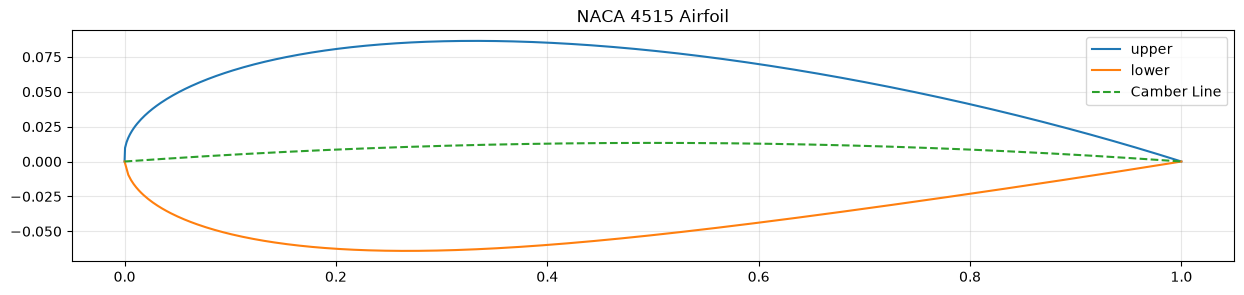

In [4]:
# Plotting the airfoil with equations
# defining a funtion for airfoil
def NACA(m, p, t, c, n):
    x = np.linspace(0, c, n)
    yt = 5 * t * (0.2969*np.sqrt(x) - 0.1260*(x) - 0.3516*(x)**2 + 0.2843*(x)**3 - 0.1036*(x)**4)
    y_c = np.zeros_like(x)
    dyc_dx = np.zeros_like(x)

    for i in range(n):
        if p!=0:
            if x[i] < p:
                y_c = (m / p**2)*(2*p*x - x**2)
                dyc_dx = (2*m/p**2)*(p - x)
            else:
                y_c = (m / (1 - p**2))*((1 - 2*p)+(2*p*x) - x**2)
                dyc_dx = (2*m/(1 - p)**2)*(p - x)
    theta = np.arctan(dyc_dx)
    xu = x - yt*np.sin(theta)
    xl = x + yt*np.sin(theta)
    yu = y_c + yt*np.cos(theta) 
    yl = y_c - yt*np.cos(theta) 
    yc = y_c
    return xu, xl, yu, yl, yc

# getting random inputs for substituting 
rng = np.random.default_rng()
n = 500
c = 1 #unit chord
m1 = rng.integers(2,5)
p1 = rng.integers(3,6)
t1 = rng.integers(8,22)
naca = f"{m1}{p1}{t1}"
print(f"Generated airfoil: NACA {naca}")
m = int(naca[0])/100
p = int(naca[1])/10
t = int(naca[2:])/100
x = np.linspace(0, c, n)
xu, xl, yu, yl, yc = NACA(m, p, t, c, n)
plt.figure(figsize=(15, 3))
plt.plot(xu, yu, label='upper')
plt.plot(xl, yl, label='lower')
plt.plot(x, yc, label='Camber Line', linestyle='--')
plt.title(f"NACA {naca} Airfoil")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

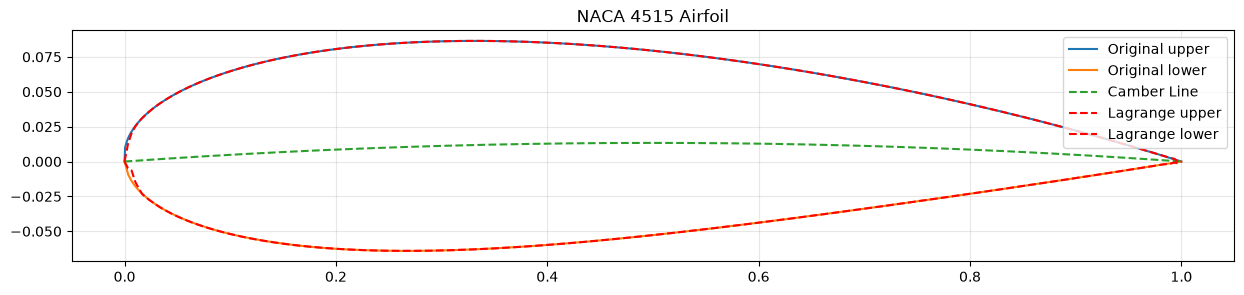

Maximum Error = 0.007006863330906892
RMS error =  0.00041268238592115093
RMS Percentage Error = 0.47738612670157904 %


In [86]:
# defining lagranges equation
def lgrng(x, y, xx):
    n = len(x)
    sum = 0
    for i in range(n):
        product = y[i]
        for j in range(n):
            if i != j:
                product = product*((xx - x[j])/(x[i] - x[j]))
        sum = sum + product
    lgrng = sum
    return lgrng
#plotting the airfoil using lagranges function
N = 56
xLu, xLl, yLu, yLl, yLc = NACA(m, p, t, c, N)
x_in = np.linspace(0, c, 300)
yL_in = lgrng(xLu, yLu, x_in)
yL_lo = lgrng(xLl, yLl, x_in)
plt.figure(figsize=(15, 3))
plt.plot(xu, yu, label='Original upper')
plt.plot(xl, yl, label='Original lower')
plt.plot(x, yc, label='Camber Line', linestyle='--')
plt.plot(x_in, yL_in, 'r--', label='Lagrange upper')
plt.plot(x_in, yL_lo, 'r--', label='Lagrange lower')
plt.title(f"NACA {naca} Airfoil")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# to quantify error between original and lagranges function
x_in = np.linspace(0, c, n)
y_up = np.interp(x_in, xu, yu)
y_lo = np.interp(x_in, xl, yl)
yL_in = lgrng(xLu, yLu, x_in)
yL_lo = lgrng(xLl, yLl, x_in)

y_ori = np.concatenate((y_up, y_lo))
y_lag = np.concatenate((yL_in, yL_lo))

max_error = np.max(np.abs(y_ori - y_lag))
print("Maximum Error =", max_error)
rms_error = np.sqrt(np.mean((y_ori - y_lag)**2))
print("RMS error = ", rms_error)
rms_percent = rms_error/np.max(np.abs(y_ori)) *100
print("RMS Percentage Error =", rms_percent, "%")

Number of inputs = 10
Maximum Error = 0.013479391416610512
RMS error =  0.0019952379456122005
RMS Percentage Error = 2.308067771241909 %
10 2.308067771241909
Number of inputs = 15
Maximum Error = 0.010950053931335007
RMS error =  0.0011494452272464554
RMS Percentage Error = 1.3296647097403484 %
15 1.3296647097403484
Number of inputs = 20
Maximum Error = 0.009695698891872532
RMS error =  0.0007918999652039736
RMS Percentage Error = 0.916060558969606 %
20 0.916060558969606
Number of inputs = 25
Maximum Error = 0.008929976119908575
RMS error =  0.0005967898640305182
RMS Percentage Error = 0.6903594904065647 %
25 0.6903594904065647
Number of inputs = 30
Maximum Error = 0.008231864076398863
RMS error =  0.0004742374892029591
RMS Percentage Error = 0.5485923456654109 %
30 0.5485923456654109
Number of inputs = 35
Maximum Error = 0.007590077717253471
RMS error =  0.0003900500813824794
RMS Percentage Error = 0.4512053431967766 %
35 0.4512053431967766
Number of inputs = 40
Maximum Error = 0.0069

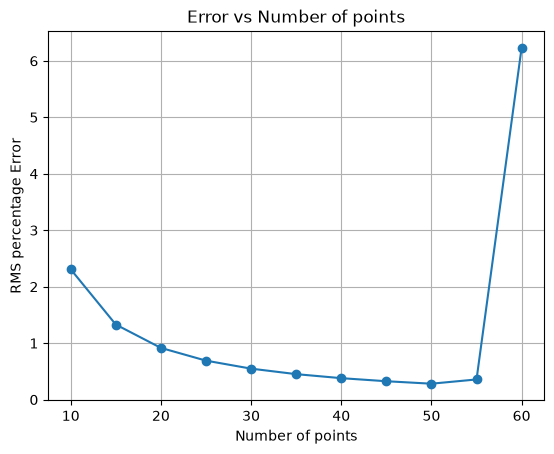

In [76]:
N_list = []
p_list = []
for N in range(10, 61, 5):
    xLu, xLl, yLu, yLl, yLc = NACA(m, p, t, c, N)
    x_in = np.linspace(0, c, n)
    yL_in = lgrng(xLu, yLu, x_in)
    yL_lo = lgrng(xLl, yLl, x_in)
    x_in = np.linspace(0, c, n)
    y_up = np.interp(x_in, xu, yu)
    y_lo = np.interp(x_in, xl, yl)
    yL_in = lgrng(xLu, yLu, x_in)
    yL_lo = lgrng(xLl, yLl, x_in)
    y_ori = np.concatenate((y_up, y_lo))
    y_lag = np.concatenate((yL_in, yL_lo))
    print("Number of inputs =", N)
    max_error = np.max(np.abs(y_ori - y_lag))
    print("Maximum Error =", max_error)
    rms_error = np.sqrt(np.mean((y_ori - y_lag)**2))
    print("RMS error = ", rms_error)
    rms_percent = rms_error/np.max(np.abs(y_ori)) *100
    print("RMS Percentage Error =", rms_percent, "%")
    N_list.append(N)              
    p_list.append(rms_percent)   
    print(N, rms_percent)
plt.plot(N_list, p_list, "o-")
plt.xlabel("Number of points")
plt.ylabel("RMS percentage Error")
plt.title("Error vs Number of points")
plt.grid(True)
plt.show()

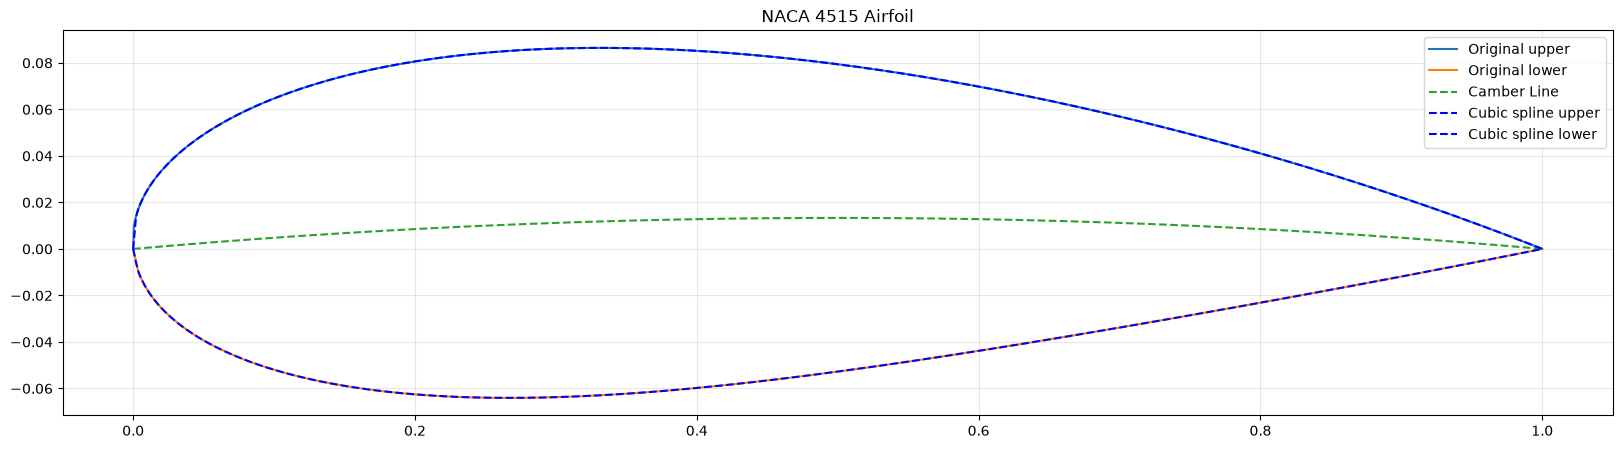

Maximum Error = 0.0004906706222518363
RMS error =  2.3130412571095753e-05
RMS Percentage Error = 0.026756989013906392 %


In [90]:
# defining function for cubic spline interplation
def cubic_spl(t, y, x):
    n = len(t) - 1
    h = np.zeros(n)
    b = np.zeros(n)
    u = np.zeros(n)
    v = np.zeros(n)
    z = np.zeros(n + 1)
 
    for i in range(n):
        h[i] = t[i + 1] - t[i]
        b[i] = 6 * (y[i + 1] - y[i]) / h[i]
 
    u[1] = 2 * (h[0] + h[1])
    v[1] = b[1] - b[0]
    for i in range(2, n):
        u[i] = 2 * (h[i - 1] + h[i]) - h[i - 1] ** 2 / u[i - 1]
        v[i] = (b[i] - b[i - 1]) - h[i - 1] * v[i - 1] / u[i - 1]
 
    for i in range(n - 1, 0, -1):
        z[i] = (v[i] - h[i] * z[i + 1]) / u[i]
 
    s = np.zeros(len(x))
    for k in range(len(x)):
        i = 0
        while i < n - 1 and x[k] > t[i + 1]:
            i += 1
        s[k] = (z[i + 1] / (6 * h[i]) * (x[k] - t[i]) ** 3
                + z[i] / (6 * h[i]) * (t[i + 1] - x[k]) ** 3
                + (y[i + 1] / h[i] - z[i + 1] * h[i] / 6) * (x[k] - t[i])
                + (y[i] / h[i] - z[i] * h[i] / 6) * (t[i + 1] - x[k]))
    return s
 
    return s
#plotting the airfoil using Cubic spline function
N = 500
xCu, xCl, yCu, yCl, yCc = NACA(m, p, t, c, N)
x_in = np.linspace(0, c, 500)
yC_in = cubic_spl(xCu, yCu, x_in)
yC_lo = cubic_spl(xCl, yCl, x_in)
plt.figure(figsize=(20, 5))
plt.plot(xu, yu, label='Original upper')
plt.plot(xl, yl, label='Original lower')
plt.plot(x, yc, label='Camber Line', linestyle='--')
plt.plot(x_in, yC_in, 'b--', label='Cubic spline upper')
plt.plot(x_in, yC_lo, 'b--', label='Cubic spline lower')
plt.title(f"NACA {naca} Airfoil")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# to quantify error between original and cubic spline function
x_in = np.linspace(0, c, 500)
y_up = np.interp(x_in, xu, yu)
y_lo = np.interp(x_in, xl, yl)
yC_in = cubic_spl(xCu, yCu, x_in)
yC_lo = cubic_spl(xCl, yCl, x_in)
y_ori = np.concatenate((y_up, y_lo))
y_Cubic = np.concatenate((yC_in, yC_lo))

max_error = np.max(np.abs(y_ori - y_Cubic))
print("Maximum Error =", max_error)
rms_error = np.sqrt(np.mean((y_ori - y_Cubic)**2))
print("RMS error = ", rms_error)
rms_percent = rms_error/np.max(np.abs(y_ori)) *100
print("RMS Percentage Error =", rms_percent, "%")

Number of inputs = 10
Maximum Error = 0.018638336761590494
RMS error =  0.0037678598306120576
RMS Percentage Error = 4.358615903791034 %
10 4.358615903791034
Number of inputs = 60
Maximum Error = 0.008991536296859271
RMS error =  0.0005505757037464579
RMS Percentage Error = 0.636899493737386 %
60 0.636899493737386
Number of inputs = 110
Maximum Error = 0.006176641980646368
RMS error =  0.000266663273481359
RMS Percentage Error = 0.3084729360975263 %
110 0.3084729360975263
Number of inputs = 160
Maximum Error = 0.003530778156607425
RMS error =  0.00014927627791191302
RMS Percentage Error = 0.17268104128488868 %
160 0.17268104128488868
Number of inputs = 210
Maximum Error = 0.0015745644713184258
RMS error =  8.044493242702481e-05
RMS Percentage Error = 0.09305775098296816 %
210 0.09305775098296816
Number of inputs = 260
Maximum Error = 0.0009062183025368847
RMS error =  4.894899979642022e-05
RMS Percentage Error = 0.056623626827615924 %
260 0.056623626827615924


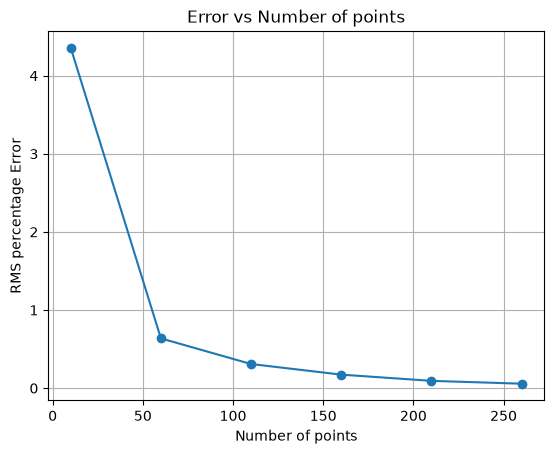

In [46]:
N_list = []
p_list = []
for N in range(10, 300, 50):
    xCu, xCl, yCu, yCl, yCc = NACA(m, p, t, c, N)
    x_in = np.linspace(0, c, n)
    yC_in = cubic_spl(xCu, yCu, x_in)
    yC_lo = cubic_spl(xCl, yCl, x_in)
    x_in = np.linspace(0, c, n)
    y_up = np.interp(x_in, xu, yu)
    y_lo = np.interp(x_in, xl, yl)
    yC_in = cubic_spl(xCu, yCu, x_in)
    yC_lo = cubic_spl(xCl, yCl, x_in)
    y_ori = np.concatenate((y_up, y_lo))
    y_Cubic = np.concatenate((yC_in, yC_lo))
    print("Number of inputs =", N)
    max_error = np.max(np.abs(y_ori - y_Cubic))
    print("Maximum Error =", max_error)
    rms_error = np.sqrt(np.mean((y_ori - y_Cubic)**2))
    print("RMS error = ", rms_error)
    rms_percent = rms_error/np.max(np.abs(y_ori)) *100
    print("RMS Percentage Error =", rms_percent, "%")
    N_list.append(N)              
    p_list.append(rms_percent)   
    print(N, rms_percent)
plt.plot(N_list, p_list, "o-")
plt.xlabel("Number of points")
plt.ylabel("RMS percentage Error")
plt.title("Error vs Number of points")
plt.grid(True)
plt.show()

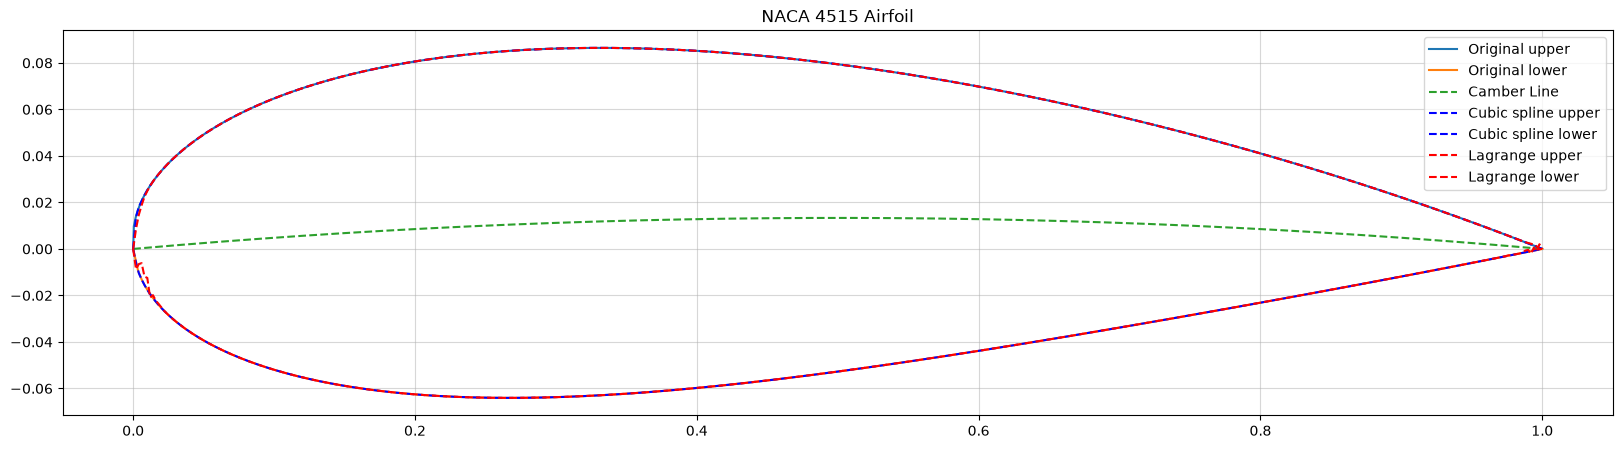

In [88]:
#comparing the original; airfoil with both lagranges and cubic spline interpolation
plt.figure(figsize=(20,5))
plt.plot(xu, yu, label='Original upper')
plt.plot(xl, yl, label='Original lower')
plt.plot(x, yc, label='Camber Line', linestyle='--')
plt.plot(x_in, yC_in, 'b--', label='Cubic spline upper')
plt.plot(x_in, yC_lo, 'b--', label='Cubic spline lower')
plt.plot(x_in, yL_in, 'r--', label='Lagrange upper')
plt.plot(x_in, yL_lo, 'r--', label='Lagrange lower')
plt.title(f"NACA {naca} Airfoil")
plt.grid(True, alpha=0.5)
plt.legend()
plt.show()

# Results and discussion

### Original airfoil making:
The airfoil was built using random values for its curve, curve position, and thickness. The plot shows the normal wing shape: a rounded nose, the thickest part near the front, and top and bottom edges tapering to a sharp tail. The centerline sits neatly in the middle, showing the base shape was drawn correctly.
### Airfoil through lagrange interpolation:
We picked $N$ sample points from range 10 to 60 along the airfoil and used a Lagrange formula to redraw the shape. The new curve hits every sampled point and traces the original wing well across the middle.\
The error percentage decreased until N reaches 56 and as it reaches above 56 the error increased exponentially, this type of errors are mainly due to the shape of airfoil, as errors stay tiny along the flatter middle of the wing, but get worse near the nose and tail. In those areas, the surface bends sharply, causing the formula to overshoot and wobble between points. this can be refered when we plot the lagrange airfoil with N value of 56 we can see some disturbances near the leading and trailing edges.
### Airfoil through Cubic Spline interpolation:
We picked $N$ sample points of range 10 to 300 along the airfoil and used Cubic spline formula to redraw the airfoil. as the numbewr of points increases we can see the decrease in error at the earlier points the decrease in error was quite large then the decrease was gradual. but still at N reaches 50 we can see some discrepancy near the leading and trailing edges.
### why choosing the spacing between data points is important:
Accuracy depends heavily on where the sample points are placed. When points are evenly spaced, too few end up at the leading and trailing edges, where the curve changes fastest. This causes higher errors at both ends.
By clustering more points near these sharp turns like leading and trailing edges and fewer in the flatter middle, the curve can track the true shape much better. This lowers both the maximum and average errors significantly improving overall accuracy without needing to add more points.

# Summary and conculsions

### Summary:
The airfoil was first created using random values for its shape and thickness. It had a normal airfoil shape with a rounded front, a thick middle part, and a sharp back. Then, Lagrange and cubic spline interpolation were used to recreate the airfoil using selected points. The new curves matched the original airfoil closely. The main errors occurred near the front and back of the airfoil where the curve changes quickly.
### Conclusions:
Cubic spline interpolation can be used to accurately recreate an airfoil shape. Comparing both lagranges and cubic spline interpolastiomn we can see that cubic spline gives more accuracy compared to lagranges as number of points increases.

# References

[Airfoil](https://en.wikipedia.org/wiki/NACA_airfoil)\
[lagrange](https://en.wikipedia.org/wiki/Lagrange_polynomial)\
[Cubic spline](https://claude.ai/chat/a814ab50-338b-4cb9-bc76-5b1846dd8ba1)